# 01 — STEW Dataset Exploration

**Goal.** Understand the raw STEW recordings *before* any processing: structure, labels, amplitude scale,
signal quality and spectral content. Nothing in this notebook modifies the data or selects features;
quality metrics are descriptive and the thresholds used here are provisional (they are justified/finalised in Stage 2).

**Sources of truth**
- Official dataset page — IEEE DataPort, DOI [10.21227/44r8-ya50](https://doi.org/10.21227/44r8-ya50) (CC BY 4.0).
- Lim, Sourina & Wang (2018), *STEW: Simultaneous Task EEG Workload Data Set*, IEEE TNSRE 26(11) — DOI [10.1109/TNSRE.2018.2872924](https://doi.org/10.1109/TNSRE.2018.2872924).

Every structural assumption below is checked against the files in code (and in `tests/test_data_loader.py`).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import welch

from data_loader import (CHANNELS, CONDITIONS, FS, N_SUBJECTS, EXPECTED_SAMPLES,
                         DEFAULT_DATA_DIR, load_all, load_ratings)
import quality as q

FIG_DIR = ROOT / "results" / "figures" / "01_exploration"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 160, "display.max_columns", 30)
COND_COLOR = {"lo": "#4C72B0", "hi": "#DD8452"}
print("data dir:", DEFAULT_DATA_DIR.relative_to(ROOT))

data dir: data/raw/STEW


## 1. Documented structure

| Item | Documentation says | Verified below |
|---|---|---|
| Subjects | 48 | file count |
| Files | `subXX_lo.txt` = **rest**, `subXX_hi.txt` = **SIMKAP multitasking test** | — (semantics can only come from docs) |
| Layout | rows = samples, columns = channels | shape |
| Channels (order) | AF3, F7, F3, FC5, T7, P7, O1, O2, P8, T8, FC6, F4, F8, AF4 (Emotiv EPOC) | column count |
| Sampling rate | 128 Hz | 2.5 min × 128 Hz = 19 200 rows |
| `ratings.txt` | CSV: subject, rating at rest, rating for test; 1–9 scale | parse + range |
| Missing ratings | subjects 5, 24, 42 | set difference |
| Units / reference | **not stated** | treated as unknown |

Important: `lo` is **not** a "low-workload task" — it is a resting recording. The binary contrast in this dataset is therefore
*rest vs. multitasking*, which differs in more than workload (eyes/motor activity, visual input, task engagement).

In [2]:
recs = load_all()
inv = pd.DataFrame([
    dict(subject=s, condition=c, n_samples=r.data.shape[0], n_channels=r.data.shape[1],
         duration_s=r.duration_s, n_nan=int(np.isnan(r.data).sum()), n_inf=int(np.isinf(r.data).sum()))
    for (s, c), r in recs.items()
])
print(f"recordings loaded: {len(recs)}  (expected {2 * N_SUBJECTS})")
print("unique shapes:", sorted({(a, b) for a, b in zip(inv.n_samples, inv.n_channels)}))
print("durations (s):", sorted(inv.duration_s.unique()))
print("total NaN:", inv.n_nan.sum(), " total Inf:", inv.n_inf.sum())
assert len(recs) == 96 and (inv.n_samples == EXPECTED_SAMPLES).all() and (inv.n_channels == 14).all()
assert inv.n_nan.sum() == 0 and inv.n_inf.sum() == 0
total_hours = inv.duration_s.sum() / 3600
print(f"total EEG: {total_hours:.2f} h, {inv.n_samples.sum() * 14:,} values")

recordings loaded: 96  (expected 96)
unique shapes: [(19200, 14)]
durations (s): [np.float64(150.0)]
total NaN: 0  total Inf: 0
total EEG: 4.00 h, 25,804,800 values


## 2. Subjective workload ratings

In [3]:
ratings = load_ratings()
missing = sorted(set(range(1, N_SUBJECTS + 1)) - set(ratings.index))
print("subjects with ratings:", len(ratings), "| missing:", missing)
print("values within 1-9:", bool(ratings.isin(range(1, 10)).all().all()))
display(ratings.describe().T.round(2))

diff = ratings.rating_test - ratings.rating_rest
print(f"test > rest for {int((diff > 0).sum())}/{len(diff)} subjects; ties: {int((diff == 0).sum())}; test < rest: {int((diff < 0).sum())}")
w = stats.wilcoxon(ratings.rating_test, ratings.rating_rest)
print(f"Wilcoxon signed-rank (paired): W={w.statistic:.1f}, p={w.pvalue:.2e}")
rho = stats.spearmanr(ratings.rating_rest, ratings.rating_test)
print(f"Spearman rho(rest, test) = {rho.statistic:.2f}, p = {rho.pvalue:.2f}")
print("\nrating counts:")
display(pd.DataFrame({c: ratings[c].value_counts().reindex(range(1, 10), fill_value=0) for c in ratings}).T)

subjects with ratings: 45 | missing: [5, 24, 42]
values within 1-9: True


,count,mean,std,min,25%,50%,75%,max
rating_rest,45.0,1.80,1.01,1.0,1.0,1.0,2.0,5.0
rating_test,45.0,6.58,1.42,4.0,5.0,7.0,8.0,9.0


test > rest for 45/45 subjects; ties: 0; test < rest: 0
Wilcoxon signed-rank (paired): W=0.0, p=4.30e-09
Spearman rho(rest, test) = 0.36, p = 0.01

rating counts:


,1,2,3,4,5,6,7,8,9
rating_rest,23,12,7,2,1,0,0,0,0
rating_test,0,0,0,3,10,7,11,11,3


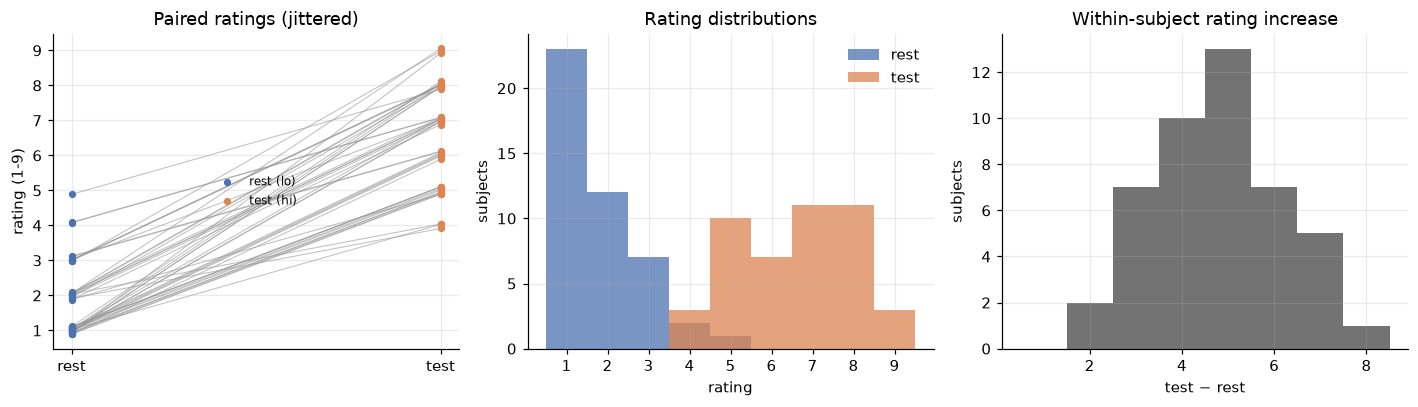

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
ax = axes[0]
jit = np.random.default_rng(0).uniform(-0.12, 0.12, len(ratings))
for (s, row), j in zip(ratings.iterrows(), jit):
    ax.plot([0, 1], [row.rating_rest + j, row.rating_test + j], color="0.6", lw=0.7, alpha=0.6)
ax.scatter(np.zeros(len(ratings)), ratings.rating_rest + jit, color=COND_COLOR["lo"], s=14, zorder=3, label="rest (lo)")
ax.scatter(np.ones(len(ratings)), ratings.rating_test + jit, color=COND_COLOR["hi"], s=14, zorder=3, label="test (hi)")
ax.set_xticks([0, 1], ["rest", "test"]); ax.set_ylabel("rating (1-9)"); ax.set_title("Paired ratings (jittered)")
ax.set_yticks(range(1, 10)); ax.legend(loc="center", frameon=False, fontsize=8)

ax = axes[1]
b = np.arange(0.5, 10.5)
ax.hist(ratings.rating_rest, bins=b, color=COND_COLOR["lo"], alpha=0.75, label="rest")
ax.hist(ratings.rating_test, bins=b, color=COND_COLOR["hi"], alpha=0.75, label="test")
ax.set_xticks(range(1, 10)); ax.set_xlabel("rating"); ax.set_ylabel("subjects"); ax.set_title("Rating distributions"); ax.legend(frameon=False)

ax = axes[2]
ax.hist(diff, bins=np.arange(0.5, 9.5), color="0.45")
ax.set_xlabel("test − rest"); ax.set_ylabel("subjects"); ax.set_title("Within-subject rating increase")
fig.tight_layout(); fig.savefig(FIG_DIR / "ratings.png", bbox_inches="tight"); plt.show()

### What the labels allow

* **Condition label (rest vs. test)** is available for all 48 subjects × 2 recordings — a balanced, paired binary target.
  Because ratings are *always* higher in the test condition, the condition label and the "higher self-reported workload"
  label coincide for every rated subject. A rest-vs-test classifier detects *task engagement*, which includes but is not limited to workload.
* **Ratings** are one number per recording (not per time window), on a 1–9 ordinal scale, available for 45 subjects.
  * Pooled over both conditions they are almost perfectly explained by condition, so regressing on them mostly re-learns the condition label.
  * The scientifically interesting signal is the **between-subject spread of test ratings** (4–9): do subjects who report higher workload
    under the same task show different EEG? That is a regression/ordinal problem with only **45 data points**, so it has very low statistical power;
    every window from a recording shares the same rating, so window-level samples are not independent.
* Any binarisation of ratings (e.g. "high" ≥ 7) would be arbitrary and is *not* done here; if used later it must be justified.

## 3. Raw amplitude scale

The documentation does not give units. Emotiv EPOC raw output is commonly described as µV with a large positive DC offset
(around 4000+), which is consistent with what we see — but we treat the unit as an assumption. The ADC quantisation step is estimated
from the smallest non-zero difference between distinct values.

In [5]:
allx = np.concatenate([r.data for r in recs.values()])
pct = np.percentile(allx, [0, 0.01, 0.1, 1, 50, 99, 99.9, 99.99, 100])
display(pd.Series(pct, index=["min", "0.01%", "0.1%", "1%", "median", "99%", "99.9%", "99.99%", "max"], name="raw value").round(1).to_frame().T)

steps = []
for r in list(recs.values())[:20]:
    for ch in range(14):
        u = np.unique(r.data[:, ch]); steps.append(np.diff(u).min())
print(f"smallest step between distinct values (20 recordings): median {np.median(steps):.3f}, min {np.min(steps):.3f}")

dc = pd.DataFrame({c: [np.mean(recs[(s, c)].data, axis=0) for s in range(1, N_SUBJECTS + 1)] for c in CONDITIONS})
dc_ch = pd.DataFrame(np.stack(dc["lo"].tolist() + dc["hi"].tolist()), columns=CHANNELS)
print("\nper-channel DC offset (mean of recording means):")
display(dc_ch.agg(["mean", "std", "min", "max"]).round(0))
del allx

,min,0.01%,0.1%,1%,median,99%,99.9%,99.99%,max
raw value,0.0,642.6,2062.6,3624.1,4316.9,4932.8,6994.9,7768.7,8401.5


smallest step between distinct values (20 recordings): median 0.510, min 0.510

per-channel DC offset (mean of recording means):


,AF3,F7,F3,FC5,T7,P7,O1,O2,P8,T8,FC6,F4,F8,AF4
mean,4397.0,4183.0,4294.0,4234.0,4490.0,4315.0,4377.0,4243.0,4214.0,4254.0,4291.0,4517.0,4429.0,4423.0
std,192.0,261.0,307.0,231.0,189.0,373.0,177.0,231.0,364.0,264.0,188.0,198.0,202.0,168.0
min,4089.0,3906.0,3702.0,3864.0,4127.0,3759.0,4089.0,3875.0,3611.0,3984.0,4012.0,4111.0,4039.0,4114.0
max,4768.0,4853.0,4739.0,4681.0,4849.0,4946.0,4722.0,4693.0,4795.0,4935.0,4624.0,4776.0,4795.0,4750.0


### Raw signal view

Subject 1, both conditions, DC offset (per-channel mean) removed for display **only** — no filtering.
Channels are vertically offset. The full 150 s view exposes slow drift and large transients; the 10 s zoom shows the oscillatory content.

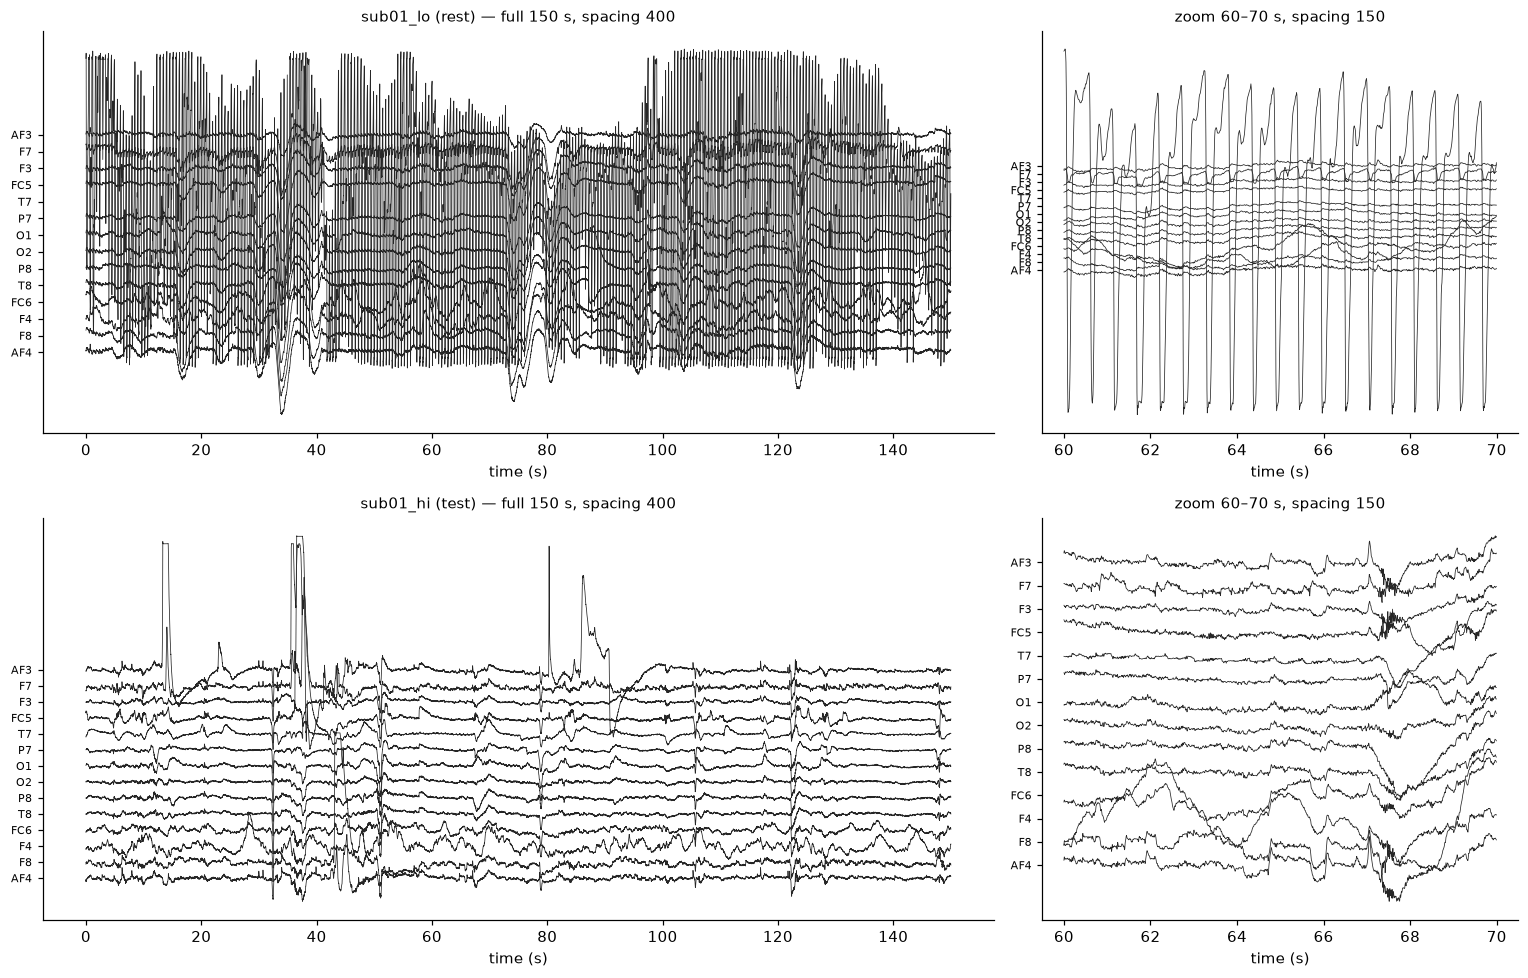

In [6]:
def stacked(ax, x, t, spacing, title):
    x = x - x.mean(axis=0)
    for i, ch in enumerate(CHANNELS):
        ax.plot(t, x[:, i] - i * spacing, lw=0.5, color="0.15")
    ax.set_yticks([-i * spacing for i in range(14)], CHANNELS, fontsize=7)
    ax.set_xlabel("time (s)"); ax.set_title(title, fontsize=10); ax.grid(False)

SUBJ = 1
fig, axes = plt.subplots(2, 2, figsize=(14, 9), gridspec_kw=dict(width_ratios=[2, 1]))
for row, c in enumerate(CONDITIONS):
    x = recs[(SUBJ, c)].data; t = np.arange(len(x)) / FS
    stacked(axes[row, 0], x, t, 400, f"sub{SUBJ:02d}_{c} ({CONDITIONS[c]}) — full 150 s, spacing 400")
    sl = slice(60 * FS, 70 * FS)
    stacked(axes[row, 1], x[sl], t[sl], 150, f"zoom 60–70 s, spacing 150")
fig.tight_layout(); fig.savefig(FIG_DIR / "raw_sub01.png", bbox_inches="tight"); plt.show()

## 4. Signal quality screening

Metrics per recording × channel (descriptive; nothing is rejected yet):

* **Flat run** — longest run of identical consecutive samples. With ~0.5-unit quantisation, short repeats are normal;
  runs > 1 s (128 samples) suggest dropout/saturation or a lost electrode contact.
* **Extreme fraction** — fraction of samples with robust z-score $|x - \mathrm{med}(x)| / (1.4826\,\mathrm{MAD}) > 6$, computed on a
  copy high-passed at 1 Hz (4th-order Butterworth, zero-phase). Without the high-pass, drift inflates the MAD and hides transients.
  The MAD is used instead of the standard deviation because it is not inflated by the very artifacts we want to find.
  For Gaussian noise the expected fraction above 6σ is ≈ 2×10⁻⁹, so anything ≳ 1 % reflects genuine non-Gaussian transients (blinks, muscle, movement, pops).
* **Large-amplitude fraction** — fraction of high-passed samples with |x| > 200 (≈ 200 µV if the unit assumption holds), a conventional
  gross-artifact threshold for scalp EEG.
* **Robust SD** — 1.4826·MAD of the high-passed signal; identifies channels whose overall level is abnormal.
* **Line-noise ratio** — PSD at 50 Hz (and 60 Hz) divided by the median of neighbouring bins. ≈ 1 means no line-noise peak.

In [7]:
rows = []
for (s, c), r in recs.items():
    x = r.data
    xh = q.highpass(x, FS, 1.0)
    flat = q.max_flat_run(x)
    ext = q.extreme_fraction(xh, 6.0)
    big = (np.abs(xh) > 200).mean(axis=0)
    rsd = np.median(np.abs(xh - np.median(xh, 0)), 0) * q.MAD_TO_SD
    for i, ch in enumerate(CHANNELS):
        rows.append(dict(subject=s, condition=c, channel=ch, max_flat_run=int(flat[i]),
                         extreme_frac=ext[i], big_frac=big[i], robust_sd=rsd[i]))
qc = pd.DataFrame(rows)
ln = pd.DataFrame([dict(subject=s, condition=c, line50=q.line_noise_ratio(r.data, FS, 50),
                        line60=q.line_noise_ratio(r.data, FS, 60)) for (s, c), r in recs.items()])

qc["flag_flat"] = qc.max_flat_run > FS
qc["flag_extreme"] = qc.extreme_frac > 0.01
qc["flag_big"] = qc.big_frac > 0.05
qc["flagged"] = qc[["flag_flat", "flag_extreme", "flag_big"]].any(axis=1)

print(f"channel-recordings: {len(qc)}; flagged by any provisional rule: {qc.flagged.sum()} ({qc.flagged.mean():.1%})")
display(qc[["flag_flat", "flag_extreme", "flag_big", "flagged"]].sum().to_frame("count").T)
print("\nrobust SD of high-passed signal (all channel-recordings):")
display(qc.robust_sd.describe(percentiles=[.05, .25, .5, .75, .95]).round(1).to_frame().T)

channel-recordings: 1344; flagged by any provisional rule: 348 (25.9%)


,flag_flat,flag_extreme,flag_big,flagged
count,30,340,24,348



robust SD of high-passed signal (all channel-recordings):


,count,mean,std,min,5%,25%,50%,75%,95%,max
robust_sd,1344.0,14.9,51.8,2.5,6.1,8.7,11.2,15.1,24.5,1835.5


In [8]:
per_rec = qc.groupby(["subject", "condition"]).agg(n_flagged=("flagged", "sum"),
                                                     worst_extreme=("extreme_frac", "max"),
                                                     worst_flat=("max_flat_run", "max")).reset_index()
per_rec = per_rec.merge(ln, on=["subject", "condition"])
print("flagged channels per recording:")
display(per_rec.n_flagged.value_counts().sort_index().to_frame("recordings").T)
print("\nflag rate by channel:")
display(qc.groupby("channel").flagged.mean().reindex(CHANNELS).round(3).to_frame("flag rate").T)
print("\nflag rate by condition:")
display(qc.groupby("condition").flagged.mean().round(3).to_frame("flag rate").T)
print("\nworst 10 recordings by #flagged channels:")
display(per_rec.sort_values(["n_flagged", "worst_extreme"], ascending=False).head(10).round(3))

flagged channels per recording:


n_flagged,0,1,2,3,4,5,6,7,8,9,10,12,13,14
recordings,21,23,9,10,6,5,4,1,3,2,2,2,1,7



flag rate by channel:


channel,AF3,F7,F3,FC5,T7,P7,O1,O2,P8,T8,FC6,F4,F8,AF4
flag rate,0.458,0.365,0.271,0.271,0.385,0.208,0.219,0.146,0.208,0.188,0.219,0.188,0.219,0.281



flag rate by condition:


condition,hi,lo
flag rate,0.326,0.192



worst 10 recordings by #flagged channels:


,subject,condition,n_flagged,worst_extreme,worst_flat,line50,line60
64,33,hi,14,0.185,420,0.024,0.605
87,44,lo,14,0.127,324,0.739,0.726
86,44,hi,14,0.117,196,4.050,0.461
68,35,hi,14,0.074,237,28.834,0.839
48,25,hi,14,0.063,4,208.372,0.816
24,13,hi,14,0.049,76,0.092,0.376
37,19,lo,14,0.046,70,23.829,0.897
75,38,lo,13,0.029,4,2.255,0.822
0,1,hi,12,0.085,110,0.517,0.835
7,4,lo,12,0.045,5,1.183,1.228


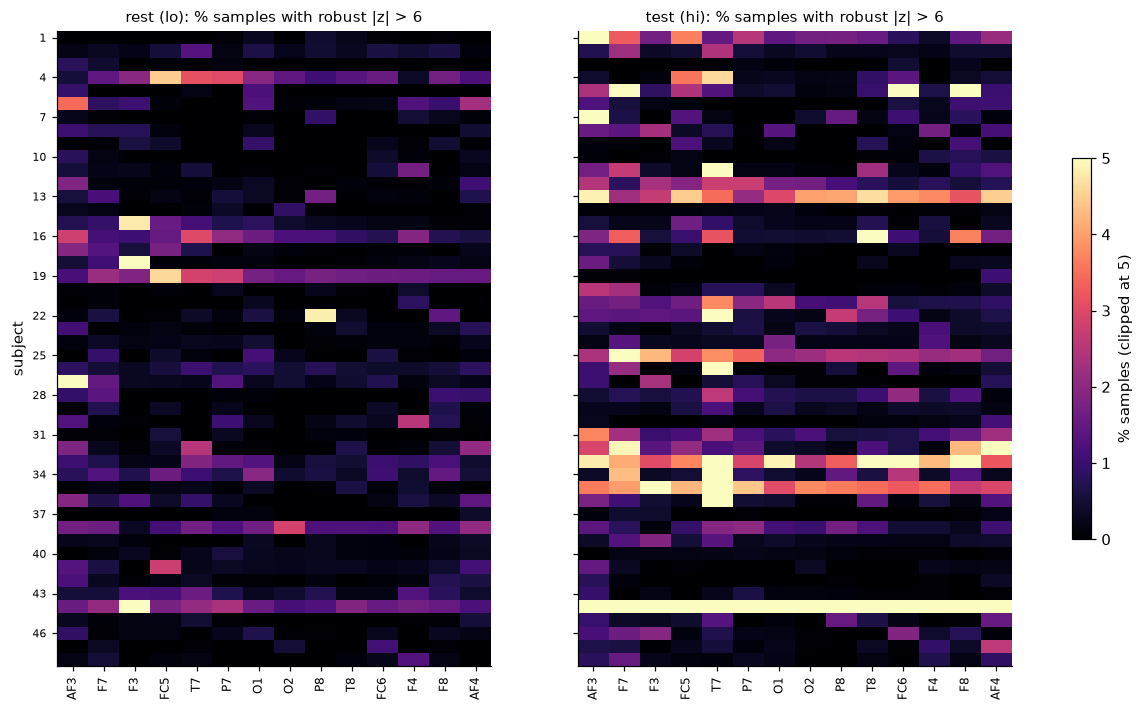

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), sharey=True)
for ax, c in zip(axes, CONDITIONS):
    m = qc[qc.condition == c].pivot(index="subject", columns="channel", values="extreme_frac")[list(CHANNELS)]
    im = ax.imshow(m.values * 100, aspect="auto", cmap="magma", vmin=0, vmax=5, interpolation="nearest")
    ax.set_xticks(range(14), CHANNELS, rotation=90, fontsize=8)
    ax.set_yticks(range(0, 48, 3), m.index[::3], fontsize=7)
    ax.set_title(f"{CONDITIONS[c]} ({c}): % samples with robust |z| > 6", fontsize=10); ax.grid(False)
axes[0].set_ylabel("subject")
fig.colorbar(im, ax=axes, shrink=0.6, label="% samples (clipped at 5)")
fig.savefig(FIG_DIR / "quality_heatmap.png", bbox_inches="tight"); plt.show()

50 Hz ratio: median 1.32; recordings with ratio > 3: 32
60 Hz ratio: median 0.83; recordings with ratio > 3: 0


,subject,condition,line50,line60
79,40,hi,284.55,0.81
49,25,hi,208.37,0.82
26,14,lo,169.50,0.92
73,37,hi,166.83,0.90
39,20,hi,86.09,0.84
85,43,hi,82.81,0.85
93,47,hi,75.23,0.83
44,23,lo,63.49,0.93
38,20,lo,44.23,0.90
95,48,hi,39.52,0.91


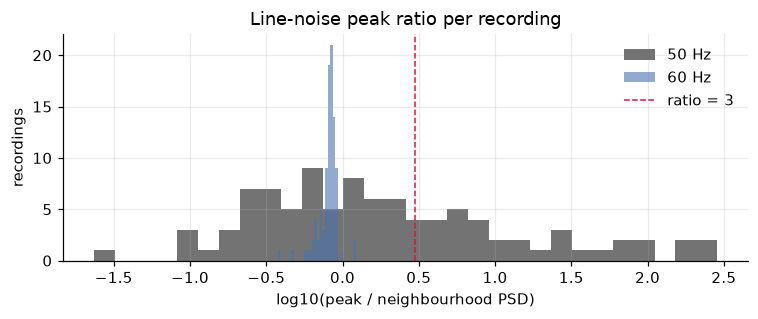

In [10]:
print("50 Hz ratio: median %.2f; recordings with ratio > 3: %d" % (ln.line50.median(), (ln.line50 > 3).sum()))
print("60 Hz ratio: median %.2f; recordings with ratio > 3: %d" % (ln.line60.median(), (ln.line60 > 3).sum()))
display(ln[ln.line50 > 3].sort_values("line50", ascending=False).round(2))

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log10(ln.line50), bins=30, color="0.45", label="50 Hz")
ax.hist(np.log10(ln.line60), bins=30, color=COND_COLOR["lo"], alpha=0.6, label="60 Hz")
ax.axvline(np.log10(3), color="crimson", ls="--", lw=1, label="ratio = 3")
ax.set_xlabel("log10(peak / neighbourhood PSD)"); ax.set_ylabel("recordings"); ax.legend(frameon=False)
ax.set_title("Line-noise peak ratio per recording")
fig.tight_layout(); fig.savefig(FIG_DIR / "line_noise.png", bbox_inches="tight"); plt.show()

### Examples of the worst-flagged recordings
Raw (DC removed) 20 s excerpt around the largest transient of the worst channel.

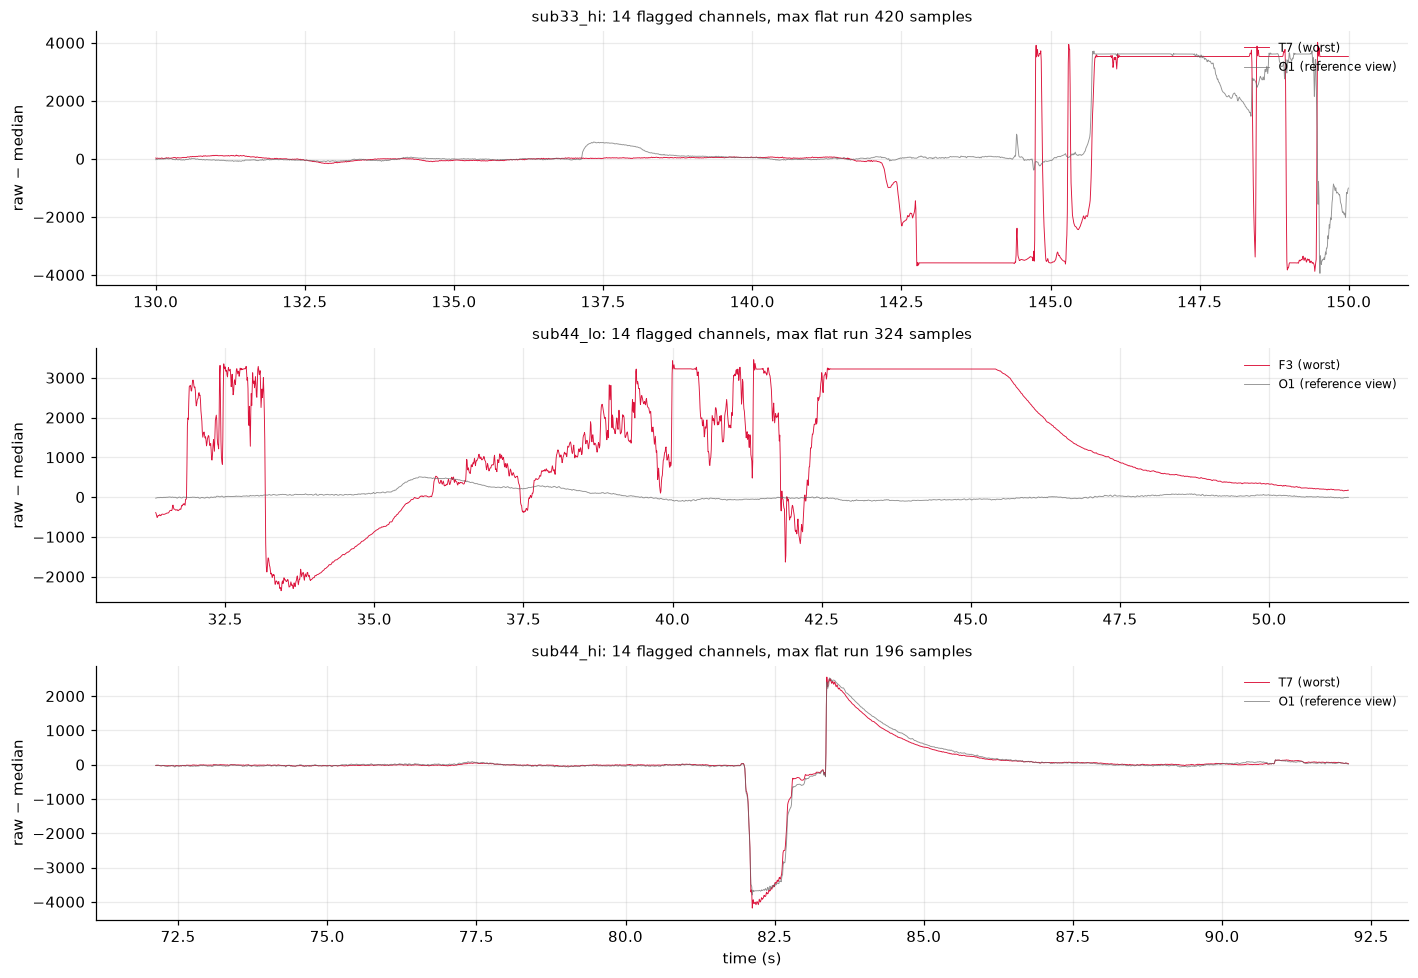

In [11]:
worst = per_rec.sort_values(["n_flagged", "worst_extreme"], ascending=False).head(3)
fig, axes = plt.subplots(len(worst), 1, figsize=(13, 3 * len(worst)))
for ax, (_, w) in zip(axes, worst.iterrows()):
    x = recs[(w.subject, w.condition)].data
    sub = qc[(qc.subject == w.subject) & (qc.condition == w.condition)]
    ch = CHANNELS.index(sub.loc[sub.extreme_frac.idxmax(), "channel"])
    xh = q.highpass(x, FS)
    centre = int(np.argmax(np.abs(xh[:, ch])))
    lo = int(np.clip(centre - 10 * FS, 0, len(x) - 20 * FS)); sl = slice(lo, lo + 20 * FS)
    t = np.arange(len(x))[sl] / FS
    ax.plot(t, x[sl, ch] - np.median(x[:, ch]), lw=0.6, color="crimson", label=f"{CHANNELS[ch]} (worst)")
    ax.plot(t, x[sl, CHANNELS.index("O1")] - np.median(x[:, CHANNELS.index("O1")]), lw=0.6, color="0.4", alpha=0.7, label="O1 (reference view)")
    ax.set_title(f"sub{w.subject:02d}_{w.condition}: {int(w.n_flagged)} flagged channels, max flat run {int(w.worst_flat)} samples", fontsize=10)
    ax.set_ylabel("raw − median"); ax.legend(frameon=False, fontsize=8, loc="upper right")
axes[-1].set_xlabel("time (s)")
fig.tight_layout(); fig.savefig(FIG_DIR / "worst_recordings.png", bbox_inches="tight"); plt.show()

## 5. Spectral overview

Power spectral density via Welch's method: the signal is split into overlapping segments (4 s Hann windows, 50 % overlap →
0.25 Hz resolution), each segment's periodogram $|X(f)|^2$ is computed, and segment periodograms are combined.
Here segments are combined with the **median** rather than the mean, so a few artifact-laden segments do not dominate.
Spectra are computed on DC-removed data and averaged in log space across subjects (geometric mean), which is appropriate because EEG power is roughly log-normally distributed across people.

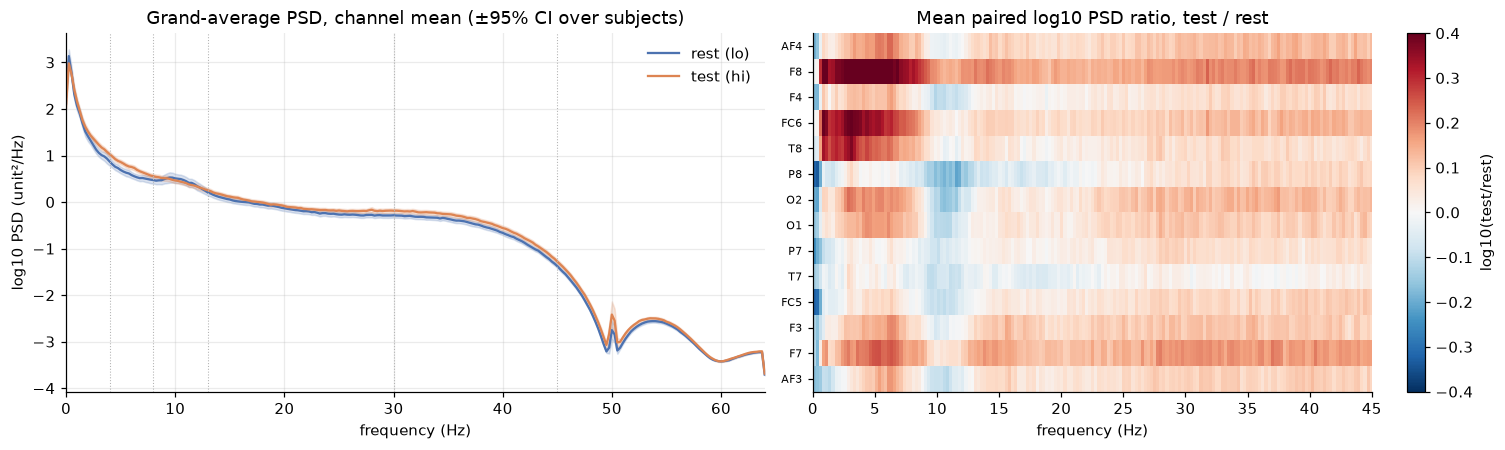

 10 Hz: grand-mean log10 PSD = 0.49
 30 Hz: grand-mean log10 PSD = -0.24
 40 Hz: grand-mean log10 PSD = -0.61
 45 Hz: grand-mean log10 PSD = -1.33
 50 Hz: grand-mean log10 PSD = -2.58
 55 Hz: grand-mean log10 PSD = -2.59
 60 Hz: grand-mean log10 PSD = -3.42
 64 Hz: grand-mean log10 PSD = -3.70


In [12]:
psd = {}
for (s, c), r in recs.items():
    f, p = welch(r.data - r.data.mean(axis=0), fs=FS, nperseg=4 * FS, noverlap=2 * FS, axis=0, average="median")
    psd[(s, c)] = p  # (freqs, channels)
logp = {c: np.stack([np.log10(psd[(s, c)]) for s in range(1, N_SUBJECTS + 1)]) for c in CONDITIONS}  # (subj, f, ch)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
for c in CONDITIONS:
    g = logp[c].mean(axis=2)  # channel-average, per subject
    m, se = g.mean(0), g.std(0) / np.sqrt(g.shape[0])
    ax.plot(f, m, color=COND_COLOR[c], label=f"{CONDITIONS[c]} ({c})")
    ax.fill_between(f, m - 1.96 * se, m + 1.96 * se, color=COND_COLOR[c], alpha=0.2)
for b in [4, 8, 13, 30, 45]:
    ax.axvline(b, color="0.7", lw=0.7, ls=":")
ax.set_xlim(0, 64); ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("log10 PSD (unit²/Hz)")
ax.set_title("Grand-average PSD, channel mean (±95% CI over subjects)"); ax.legend(frameon=False)

ax = axes[1]
d = (logp["hi"] - logp["lo"]).mean(axis=0)  # (f, ch) mean paired log-ratio
im = ax.imshow(d.T, aspect="auto", origin="lower", extent=[f[0], f[-1], -0.5, 13.5], cmap="RdBu_r", vmin=-0.4, vmax=0.4)
ax.set_yticks(range(14), CHANNELS, fontsize=7); ax.set_xlim(0, 45); ax.grid(False)
ax.set_xlabel("frequency (Hz)"); ax.set_title("Mean paired log10 PSD ratio, test / rest")
fig.colorbar(im, ax=ax, label="log10(test/rest)")
fig.tight_layout(); fig.savefig(FIG_DIR / "psd_overview.png", bbox_inches="tight"); plt.show()

gm = np.mean([logp[c].mean(axis=(0, 2)) for c in CONDITIONS], axis=0)
for fr in [10, 30, 40, 45, 50, 55, 60, 64]:
    print(f"{fr:>3} Hz: grand-mean log10 PSD = {gm[np.argmin(np.abs(f - fr))]:.2f}")

## 6. Descriptive rest-vs-test band power (exploratory)

Relative band power per channel = band power / total power in 1–45 Hz (integrated PSD, trapezoid rule). Band edges here are the
conventional ones (δ 1–4, θ 4–8, α 8–13, β 13–30, γ 30–45 Hz); their justification is revisited in Stage 3.
For each band × channel we test the **paired** within-subject difference with a Wilcoxon signed-rank test and correct for 70 comparisons
with Benjamini–Hochberg FDR.

> This is descriptive only. It is computed on the full dataset, so it must **not** be used to choose features or channels for the
> models — doing so would leak information from test folds into model design.

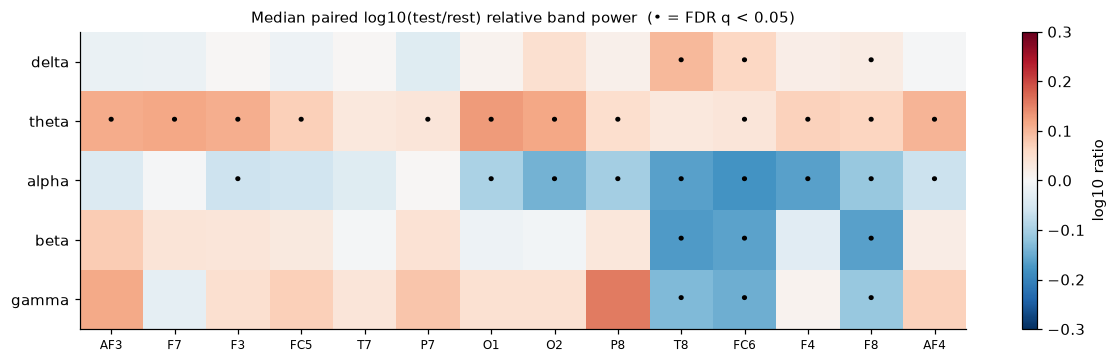

significant band×channel cells: 30 / 70


,n_sig,median_log_ratio,frac_subj_increase
band,,,
delta,3,0.007,0.527
theta,12,0.071,0.744
alpha,9,-0.079,0.371
beta,3,0.009,0.479
gamma,3,0.046,0.528


In [13]:
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 45)}
def rel_power(p):
    tot_m = (f >= 1) & (f <= 45)
    tot = np.trapezoid(p[tot_m], f[tot_m], axis=0)
    out = {}
    for b, (lo, hi) in BANDS.items():
        m = (f >= lo) & (f <= hi)
        out[b] = np.trapezoid(p[m], f[m], axis=0) / tot
    return out

rp = {(s, c): rel_power(psd[(s, c)]) for (s, c) in psd}
res = []
for b in BANDS:
    for i, ch in enumerate(CHANNELS):
        lo = np.array([rp[(s, "lo")][b][i] for s in range(1, N_SUBJECTS + 1)])
        hi = np.array([rp[(s, "hi")][b][i] for s in range(1, N_SUBJECTS + 1)])
        w = stats.wilcoxon(hi, lo)
        res.append(dict(band=b, channel=ch, median_log_ratio=np.median(np.log10(hi / lo)),
                        frac_subj_increase=np.mean(hi > lo), p=w.pvalue))
res = pd.DataFrame(res)
res["p_fdr"] = stats.false_discovery_control(res.p, method="bh")
res["significant"] = res.p_fdr < 0.05

piv = res.pivot(index="band", columns="channel", values="median_log_ratio").loc[list(BANDS), list(CHANNELS)]
sig = res.pivot(index="band", columns="channel", values="significant").loc[list(BANDS), list(CHANNELS)]
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(piv.values, cmap="RdBu_r", vmin=-0.3, vmax=0.3, aspect="auto")
for (r_, c_), v in np.ndenumerate(sig.values):
    if v: ax.text(c_, r_, "•", ha="center", va="center", fontsize=12)
ax.set_xticks(range(14), CHANNELS, fontsize=8); ax.set_yticks(range(5), list(BANDS)); ax.grid(False)
ax.set_title("Median paired log10(test/rest) relative band power  (• = FDR q < 0.05)", fontsize=10)
fig.colorbar(im, ax=ax, label="log10 ratio")
fig.tight_layout(); fig.savefig(FIG_DIR / "band_power_contrast.png", bbox_inches="tight"); plt.show()

print("significant band×channel cells:", int(res.significant.sum()), "/", len(res))
display(res.groupby("band").agg(n_sig=("significant", "sum"), median_log_ratio=("median_log_ratio", "median"),
                                frac_subj_increase=("frac_subj_increase", "mean")).loc[list(BANDS)].round(3))

## 7. Save reproducible outputs

In [14]:
OUT = ROOT / "results" / "01_exploration"
OUT.mkdir(parents=True, exist_ok=True)
qc.to_csv(OUT / "quality_channel_level.csv", index=False)
per_rec.to_csv(OUT / "quality_recording_level.csv", index=False)
res.to_csv(OUT / "band_power_contrast.csv", index=False)

summary = {
    "dataset": {"n_subjects": N_SUBJECTS, "n_recordings": len(recs), "fs_hz": FS, "channels": list(CHANNELS),
                "samples_per_recording": EXPECTED_SAMPLES, "duration_s": EXPECTED_SAMPLES / FS,
                "conditions": CONDITIONS, "nan_values": int(inv.n_nan.sum()), "inf_values": int(inv.n_inf.sum())},
    "ratings": {"n_subjects_rated": int(len(ratings)), "missing_subjects": missing,
                "rest": ratings.rating_rest.describe().round(3).to_dict(),
                "test": ratings.rating_test.describe().round(3).to_dict(),
                "n_test_gt_rest": int((diff > 0).sum()),
                "wilcoxon_p": float(stats.wilcoxon(ratings.rating_test, ratings.rating_rest).pvalue),
                "spearman_rest_test": float(rho.statistic)},
    "quality": {"provisional_rules": {"flat_run_samples_gt": FS, "extreme_frac_gt": 0.01, "robust_z_k": 6,
                                      "big_abs_gt": 200, "big_frac_gt": 0.05, "highpass_hz": 1.0},
                "channel_recordings_flagged": int(qc.flagged.sum()), "channel_recordings_total": int(len(qc)),
                "recordings_with_any_flag": int((per_rec.n_flagged > 0).sum()),
                "flag_rate_by_condition": qc.groupby("condition").flagged.mean().round(4).to_dict(),
                "line50_median_ratio": float(ln.line50.median()),
                "recordings_line50_ratio_gt3": ln.loc[ln.line50 > 3, ["subject", "condition"]].values.tolist()},
    "band_contrast": {"n_significant_fdr05": int(res.significant.sum()), "n_tests": int(len(res))},
}
with open(OUT / "summary.json", "w") as fh:
    json.dump(summary, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("wrote:", *[p.relative_to(ROOT) for p in sorted(OUT.iterdir())], sep="\n  ")
print("figures:", *[p.relative_to(ROOT) for p in sorted(FIG_DIR.iterdir())], sep="\n  ")

wrote:
  results/01_exploration/band_power_contrast.csv
  results/01_exploration/quality_channel_level.csv
  results/01_exploration/quality_recording_level.csv
  results/01_exploration/summary.json
figures:
  results/figures/01_exploration/band_power_contrast.png
  results/figures/01_exploration/line_noise.png
  results/figures/01_exploration/psd_overview.png
  results/figures/01_exploration/quality_heatmap.png
  results/figures/01_exploration/ratings.png
  results/figures/01_exploration/raw_sub01.png
  results/figures/01_exploration/worst_recordings.png


## 8. Findings and implications for Stage 2+

**Structure (verified).** 96 recordings (48 subjects × {rest, test}), each 19 200 × 14 = 150 s at 128 Hz, no NaN/Inf.
Total 4.0 h of EEG. Ratings exist for 45 subjects (5, 24, 42 missing), all within 1–9.

**Labels.**
- `lo` = resting state and `hi` = SIMKAP multitasking (per documentation). The natural, fully-supported target is **binary rest vs. test**,
  balanced 48/48 and paired within subject.
- Every rated subject reports higher workload in the test (45/45, Wilcoxon p ≈ 4×10⁻⁹; rest median 1, test median 7), so the self-reports
  *support* the interpretation of `hi` as the higher-workload condition — but the contrast is rest vs. task, not low- vs. high-difficulty task.
  Results must be described as "task-induced workload/engagement", not as a graded workload estimator.
- Test ratings span 4–9 (45 values). Predicting them from EEG is a possible secondary regression with very low power; rest ratings are mostly 1–2
  and carry little variance. Rest and test ratings correlate weakly (Spearman ρ ≈ 0.36), hinting at an individual response-style bias.

**Amplitude.** Large per-channel DC offset (~4200–4500) plus slow drift dominate raw variance → a high-pass filter is required before any
amplitude/spectral statistic. Quantisation step 0.51 units (consistent with a 14-bit Emotiv ADC in µV, unit still unconfirmed by the dataset docs).
Values span 0 to ~8400, i.e. the ADC rails are reached in some recordings (saturation).

**Quality.** Under provisional rules ~26 % of channel-recordings are flagged; 21/96 recordings have no flagged channel, 7 have all 14 flagged.
Artifact types observed: rail saturation and contact loss (long flat runs up to 3.3 s), a periodic ~1.5 Hz, very large waveform on T7 of sub01_lo (heart-rate-like; likely pulse
artifact or poor contact — robust SD ≈ 1840 vs ≈ 15 on the other channels), and common-mode transients identical across all channels (sub44_hi), which suggest reference-electrode disturbances.
AF3, T7 and F7 are flagged most often (frontal/temporal: eye and muscle exposure).
**Test recordings are flagged more often than rest (32.6 % vs 19.2 %)** — artifact load is itself correlated with the label. A classifier could
partially succeed by detecting movement/eye/muscle activity rather than brain-state; Stage 2 must handle artifacts symmetrically and Stage 5 should check this confound.

**Spectrum.** 1/f-like EEG spectrum with an alpha peak (~10 Hz) clearer at rest. Power drops sharply from ~42 Hz and shows notch-shaped dips at 50 and
60 Hz, consistent with the headset's on-board filtering, so content above ~45 Hz is not usable — this sets the upper analysis limit.
50 Hz line noise is absent in most recordings (median peak ratio 1.3) but present in 32/96 (ratio > 3, up to ~285); 60 Hz is never present.
Since 50 Hz lies above the 45 Hz analysis band, a low-pass at 45 Hz may make a dedicated notch unnecessary — to be verified in Stage 2.

**Rest vs test (descriptive only).** Relative theta increases in the test (74 % of subjects per channel on average; 12/14 channels FDR-significant)
and relative alpha decreases (9/14 channels), the classic engagement/workload pattern. Right fronto-temporal channels (F8, FC6, T8) show the
largest broadband low-frequency increases, which overlap with likely ocular/EMG sources; this is a contamination risk, not evidence of neural workload.

**Implications for Stage 2 (preprocessing) to discuss:**
1. High-pass (~0.5–1 Hz) to remove DC/drift; low-pass ≤ 45 Hz given the on-board roll-off; evaluate whether a 50 Hz notch is still needed.
2. Window-level artifact handling (e.g. reject windows with rail values, long flat runs, or robust-z excursions), applied identically to both conditions,
   with rejection counts reported per condition.
3. Consider re-referencing (common average) to suppress common-mode transients — and document the trade-off with 14 non-uniformly placed electrodes.
4. Segmentation into fixed windows, with all windows of a subject kept in the same CV fold (GroupKFold / LOSO by subject).